<a href="https://colab.research.google.com/github/jaswanth424/MachineLearning/blob/main/CarSalePrediction_Submit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Used-Vehicle Selling Price Prediction
Linear Regression Report

Business question: Using information available when a vehicle is prepared for sale, how accurately can we estimate the selling price of vehicle?

This notebook explores the supplied dealership dataset, documents preparation decisions, fits a linear regression model, and evaluates it on a held-out test set. LISTING_DAYS is excluded from all predictors because it is not known at prediction time. The target is SELLING_PRICE in Canadian dollars.

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Import the test data csv file

In [80]:
df = pd.read_csv('/content/Used_vehicle_data.csv')

## 1. Exploratory data analysis
### Dataset size, structure, and data quality
The first checks summarize the number of observations and columns, data types, missingness, duplicate rows, and the target distribution. Missing target values cannot be used for supervised training, while missing predictor values can be imputed inside a training-only preprocessing pipeline.

In [81]:
# check if df columns has mixed data types
mixed_cols = [col for col in df.columns if infer_dtype(df[col]).startswith("mixed")]
print("Columns with mixed types:", mixed_cols)

Columns with mixed types: []


In [82]:
display(df)

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
0,Mercedes-Benz,GLA,2010,193254.0,1.8,Gasoline,Automatic,Sedan,AWD,4.0,5.0,0.0,2.0,Red,40.0,0.0,7.0,39257.66
1,Nissan,Frontier,2021,58800.0,5.7,Gasoline,Automatic,SUV,FWD,4.0,5.0,1.0,3.0,Black,71.0,0.0,2.0,42237.72
2,Hyundai,Palisade,2017,127591.0,2.0,Hybrid,Dual-Clutch,SUV,AWD,5.0,6.0,1.0,1.0,Brown,23.0,0.0,7.0,45240.28
3,BMW,X3,2015,170698.0,2.5,Gasoline,Automatic,Sedan,4WD,4.0,7.0,1.0,2.0,Silver,94.0,0.0,9.0,46287.33
4,Honda,Accord,2022,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1810,Volkswagen,Golf,2023,17453.0,6.2,Plug-in Hybrid,CVT,Sedan,FWD,5.0,5.0,0.0,1.0,White,70.0,1.0,8.0,61388.42
1811,Dodge,Charger,2022,52264.0,1.5,Gasoline,Automatic,Hatchback,AWD,5.0,4.0,0.0,1.0,Red,38.0,0.0,7.0,50397.53
1812,Lexus,LS,2023,14516.0,3.5,Gasoline,Automatic,Sedan,AWD,4.0,4.0,0.0,2.0,Brown,76.0,0.0,9.0,75960.00
1813,Nissan,Sentra,2010,211122.0,5.0,Gasoline,Automatic,Truck,FWD,4.0,5.0,0.0,2.0,Green,102.0,1.0,4.0,24357.65


In [83]:
display(df['MAKE'].hasnans)

False

In [84]:
print(df.columns[df.isna().any()])

Index(['KILOMETRES', 'ENGINE_SIZE', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE',
       'DRIVETRAIN', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'COLOUR',
       'LISTING_DAYS', 'HAS_WARRANTY', 'CONDITION_SCORE', 'SELLING_PRICE'],
      dtype='object')


In [85]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("missing_count").to_frame())
print(f"\nExact duplicate rows: {df.duplicated().sum()}")
print(f"Rows missing target SELLING_PRICE: {df['SELLING_PRICE'].isna().sum()}")

,missing_count
COLOUR,54
ENGINE_SIZE,54
DRIVETRAIN,45
OWNERS,37
CONDITION_SCORE,37
ACCIDENTS,36
KILOMETRES,36
TRANSMISSION,27
HAS_WARRANTY,27
FUEL_TYPE,19



Exact duplicate rows: 15
Rows missing target SELLING_PRICE: 10


In [86]:
df[df.isna().any(axis=1)]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
4,Honda,Accord,2022,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51
5,Kia,Sorento,2011,174760.0,5.0,Gasoline,Automatic,Sedan,NaN,4.0,4.0,1.0,3.0,Blue,103.0,0.0,9.0,25650.55
8,GMC,Canyon,2014,133487.0,1.6,Gasoline,Dual-Clutch,Sedan,FWD,4.0,NaN,0.0,1.0,Blue,32.0,0.0,5.0,23478.89
9,Jaguar,XF,2018,101490.0,2.0,Gasoline,Automatic,Sedan,FWD,2.0,5.0,3.0,3.0,NaN,40.0,1.0,8.0,42133.82
21,Hyundai,Santa Fe,2022,38703.0,2.0,Gasoline,Manual,NaN,FWD,4.0,5.0,0.0,3.0,White,76.0,1.0,5.0,51659.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1794,RAM,ProMaster,2020,36824.0,2.4,Gasoline,Automatic,SUV,AWD,4.0,7.0,1.0,2.0,NaN,66.0,1.0,3.0,47472.00
1796,Audi,A4,2010,216523.0,3.6,Gasoline,Automatic,SUV,RWD,4.0,5.0,NaN,3.0,Red,60.0,1.0,7.0,44143.89
1798,Dodge,Charger,2017,105760.0,NaN,Diesel,Automatic,Sedan,FWD,4.0,5.0,2.0,2.0,Blue,113.0,1.0,10.0,39016.51
1799,Mercedes-Benz,S-Class,2011,189710.0,2.5,Gasoline,Automatic,Wagon,AWD,5.0,5.0,0.0,NaN,Blue,63.0,0.0,9.0,38523.19


## Numerical distributions and unusual values

The numerical summaries and plots help identify skew, implausible values, and high-price observations. A statistical outlier is not automatically an error, so values are only corrected when they violate clear domain rules; unusual but plausible values are retained and their influence is considered during evaluation.

,count,mean,std,min,1%,5%,50%,95%,99%,max
YEAR,1815.0,2016.46,4.12,1992.00,2010.00,2010.00,2016.00,2023.00,2023.00,2029.0
KILOMETRES,1779.0,127023.46,83709.00,-272858.00,500.00,17210.60,121216.00,257917.60,295972.30,956421.0
ENGINE_SIZE,1761.0,2.73,1.13,0.00,1.50,1.50,2.40,5.70,6.20,6.2
DOORS,1797.0,4.04,0.77,2.00,2.00,2.00,4.00,5.00,5.00,5.0
SEATS,1797.0,5.61,1.22,2.00,2.00,4.00,5.00,8.00,8.00,8.0
ACCIDENTS,1779.0,0.53,0.84,0.00,0.00,0.00,0.00,2.00,3.00,3.0
OWNERS,1778.0,1.79,0.87,1.00,1.00,1.00,2.00,4.00,4.00,4.0
LISTING_DAYS,1797.0,60.44,35.11,-119.00,2.00,7.00,61.00,115.00,119.00,119.0
HAS_WARRANTY,1788.0,0.43,0.49,0.00,0.00,0.00,0.00,1.00,1.00,1.0
CONDITION_SCORE,1778.0,7.16,1.98,0.00,1.00,3.00,8.00,10.00,10.00,11.0


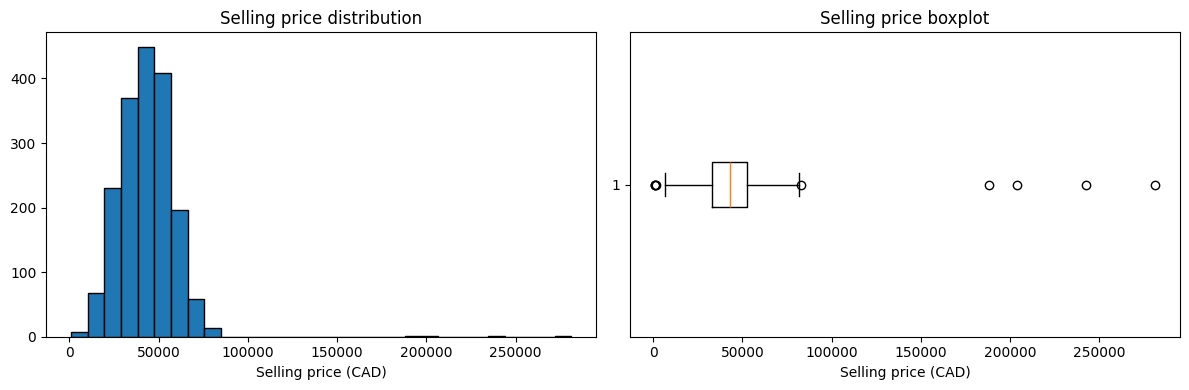

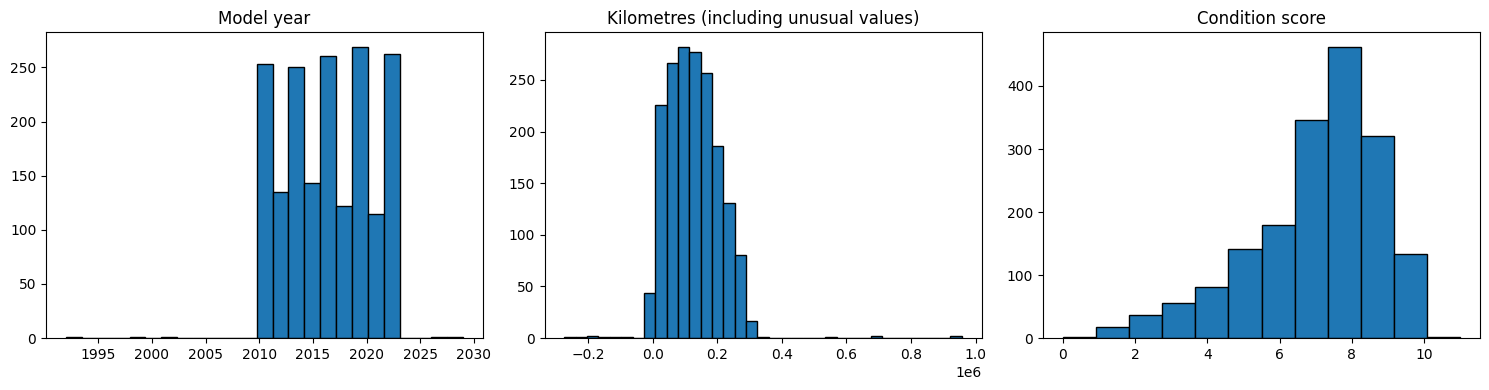

Potential domain-rule violations:


,row_count
Negative kilometres,8
Year after 2026,2
Condition score outside 1–10,4
Non-positive selling price,0
Engine size <= 0,5


In [87]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe(percentiles=[.01, .05, .50, .95, .99]).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["SELLING_PRICE"].dropna(), bins=30, edgecolor="black")
axes[0].set_title("Selling price distribution")
axes[0].set_xlabel("Selling price (CAD)")
axes[1].boxplot(df["SELLING_PRICE"].dropna(), vert=False)
axes[1].set_title("Selling price boxplot")
axes[1].set_xlabel("Selling price (CAD)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["YEAR"].dropna(), bins=25, edgecolor="black")
axes[0].set_title("Model year")
axes[1].hist(df["KILOMETRES"].dropna(), bins=35, edgecolor="black")
axes[1].set_title("Kilometres (including unusual values)")
axes[2].hist(df["CONDITION_SCORE"].dropna(), bins=12, edgecolor="black")
axes[2].set_title("Condition score")
plt.tight_layout()
plt.show()

print("Potential domain-rule violations:")
checks = {
    "Negative kilometres": int((df["KILOMETRES"] < 0).sum()),
    "Year after 2026": int((df["YEAR"] > 2026).sum()),
    "Condition score outside 1–10": int((~df["CONDITION_SCORE"].between(1, 10) & df["CONDITION_SCORE"].notna()).sum()),
    "Non-positive selling price": int((df["SELLING_PRICE"] <= 0).sum()),
    "Engine size <= 0": int((df["ENGINE_SIZE"] <= 0).sum()),
}
display(pd.Series(checks, name="row_count").to_frame())


## Relationships with selling price

The following summaries and plots focus on interpretable relationships with price. These are exploratory associations, not causal effects; vehicle age, model, condition, mileage, and body style may be related to one another.

YEAR: Pearson correlation with selling price = 0.601 (n=1805)
KILOMETRES: Pearson correlation with selling price = -0.542 (n=1769)
ENGINE_SIZE: Pearson correlation with selling price = 0.079 (n=1751)
ACCIDENTS: Pearson correlation with selling price = -0.120 (n=1769)
OWNERS: Pearson correlation with selling price = -0.019 (n=1768)
CONDITION_SCORE: Pearson correlation with selling price = 0.215 (n=1768)


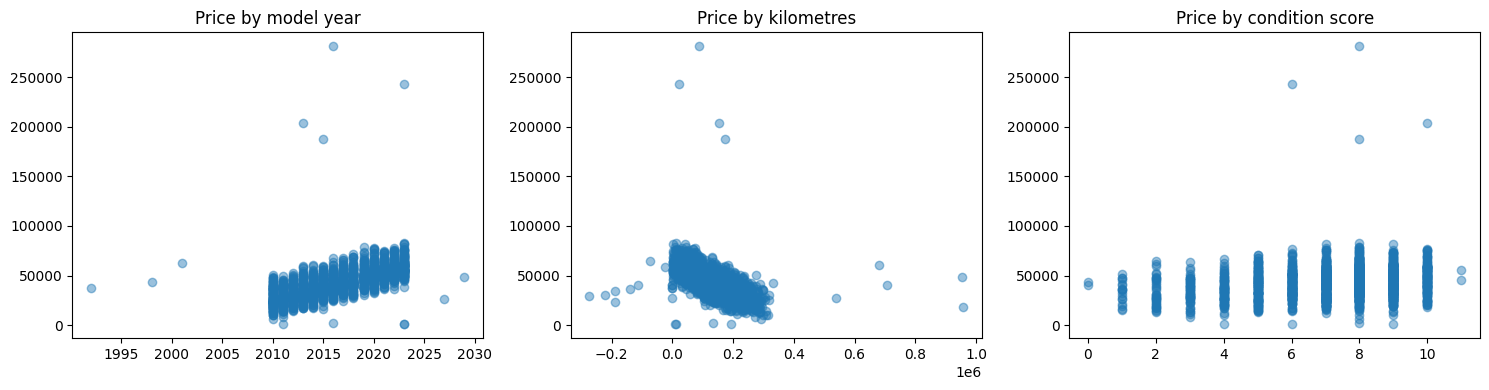

Selling price by body type:


,count,median,mean
BODY_TYPE,,,
Truck,271,47758.62,47594.03
SUV,578,45740.62,46024.49
NaN,18,41715.91,41298.44
Coupe,123,41486.08,40438.44
Minivan,100,40732.94,41675.07
Sedan,495,40069.13,40528.77
Hatchback,158,38026.78,38465.36
Wagon,62,37423.55,38689.26


Most frequent makes (counts):


,count
MAKE,
Toyota,210
Honda,184
Ford,150
Chevrolet,126
Hyundai,114
Nissan,108
BMW,90
Kia,84
Mercedes-Benz,75


Median price by fuel type:


,median_price_CAD
FUEL_TYPE,
HYBRID,69009.28
diesel,57679.66
hybrid,49373.73
Electric,47554.81
Plug-in Hybrid,46449.80
gasoline,45583.89
Diesel,44250.77
Hybrid,44210.63
Gasoline,41602.05


In [88]:
# Price relationships with numeric variables
for col in ["YEAR", "KILOMETRES", "ENGINE_SIZE", "ACCIDENTS", "OWNERS", "CONDITION_SCORE"]:
    subset = df[[col, "SELLING_PRICE"]].dropna()
    corr = subset[col].corr(subset["SELLING_PRICE"])
    print(f"{col}: Pearson correlation with selling price = {corr:.3f} (n={len(subset)})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(df["YEAR"], df["SELLING_PRICE"], alpha=.45)
axes[0].set_title("Price by model year")
axes[1].scatter(df["KILOMETRES"], df["SELLING_PRICE"], alpha=.45)
axes[1].set_title("Price by kilometres")
axes[2].scatter(df["CONDITION_SCORE"], df["SELLING_PRICE"], alpha=.45)
axes[2].set_title("Price by condition score")
plt.tight_layout()
plt.show()

print("Selling price by body type:")
display(df.groupby("BODY_TYPE", dropna=False)["SELLING_PRICE"].agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(2))
print("Most frequent makes (counts):")
display(df["MAKE"].value_counts().head(10).rename_axis("MAKE").to_frame("count"))
print("Median price by fuel type:")
display(df.groupby("FUEL_TYPE", dropna=False)["SELLING_PRICE"].median().sort_values(ascending=False).rename("median_price_CAD").to_frame().round(2))


## 2. Data preparation

#### Individual variables
Decisions are summarized below. Numeric missing values are imputed with the training-set median; categorical missing values are imputed with the most frequent training-set category. One-hot encoding is used for categorical features so that linear regression does not treat category labels as ordered quantities.

In [89]:
TARGET = "SELLING_PRICE"
EXCLUDED = ["LISTING_DAYS", TARGET]

model_df = df.loc[df[TARGET].notna()].copy()

# Apply clear domain-rule corrections before splitting; do not use target values to make these decisions.
model_df.loc[model_df["YEAR"] > 2026, "YEAR"] = np.nan
model_df.loc[model_df["KILOMETRES"] < 0, "KILOMETRES"] = np.nan
model_df.loc[model_df["ENGINE_SIZE"] <= 0, "ENGINE_SIZE"] = np.nan
model_df.loc[~model_df["CONDITION_SCORE"].between(1, 10), "CONDITION_SCORE"] = np.nan

display(model_df)

X = model_df.drop(columns=EXCLUDED)
y = model_df[TARGET]

# # Categorical and numeric columns are inferred from their source dtypes.
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Rows available after dropping missing target: {len(model_df):,}")
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Predictor count before encoding: {X.shape[1]}")
print("LISTING_DAYS in predictors?", "LISTING_DAYS" in X.columns)
print("Categorical predictors:", categorical_features)
print("Numeric predictors:", numeric_features)

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
0,Mercedes-Benz,GLA,2010.0,193254.0,1.8,Gasoline,Automatic,Sedan,AWD,4.0,5.0,0.0,2.0,Red,40.0,0.0,7.0,39257.66
1,Nissan,Frontier,2021.0,58800.0,5.7,Gasoline,Automatic,SUV,FWD,4.0,5.0,1.0,3.0,Black,71.0,0.0,2.0,42237.72
2,Hyundai,Palisade,2017.0,127591.0,2.0,Hybrid,Dual-Clutch,SUV,AWD,5.0,6.0,1.0,1.0,Brown,23.0,0.0,7.0,45240.28
3,BMW,X3,2015.0,170698.0,2.5,Gasoline,Automatic,Sedan,4WD,4.0,7.0,1.0,2.0,Silver,94.0,0.0,9.0,46287.33
4,Honda,Accord,2022.0,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1810,Volkswagen,Golf,2023.0,17453.0,6.2,Plug-in Hybrid,CVT,Sedan,FWD,5.0,5.0,0.0,1.0,White,70.0,1.0,8.0,61388.42
1811,Dodge,Charger,2022.0,52264.0,1.5,Gasoline,Automatic,Hatchback,AWD,5.0,4.0,0.0,1.0,Red,38.0,0.0,7.0,50397.53
1812,Lexus,LS,2023.0,14516.0,3.5,Gasoline,Automatic,Sedan,AWD,4.0,4.0,0.0,2.0,Brown,76.0,0.0,9.0,75960.00
1813,Nissan,Sentra,2010.0,211122.0,5.0,Gasoline,Automatic,Truck,FWD,4.0,5.0,0.0,2.0,Green,102.0,1.0,4.0,24357.65


Rows available after dropping missing target: 1,805
Training rows: 1,444 | Test rows: 361
Predictor count before encoding: 16
LISTING_DAYS in predictors? False
Categorical predictors: ['MAKE', 'MODEL', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE', 'DRIVETRAIN', 'COLOUR']
Numeric predictors: ['YEAR', 'KILOMETRES', 'ENGINE_SIZE', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'HAS_WARRANTY', 'CONDITION_SCORE']


## 3. Model
A standard ordinary least-squares linear regression model is used. Numeric features are median-imputed and standardized; categorical features are imputed and one-hot encoded, with one reference category dropped to reduce exact dummy-variable redundancy. The preprocessing and regression steps are fitted together in a single pipeline.


In [90]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model fitted successfully.")
print(f"Encoded feature count: {model.named_steps['preprocessor'].transform(X_train).shape[1]}")
display(pd.DataFrame({
    "Actual selling price (CAD)": y_test.iloc[:10].values,
    "Predicted selling price (CAD)": y_pred[:10],
    "Error (predicted - actual)": y_pred[:10] - y_test.iloc[:10].values
}).round(2))

Model fitted successfully.
Encoded feature count: 267


,Actual selling price (CAD),Predicted selling price (CAD),Error (predicted - actual)
0,54613.29,61733.91,7120.62
1,20465.98,23823.10,3357.12
2,41607.86,39584.12,-2023.74
3,42968.19,42106.83,-861.36
4,18621.38,17491.76,-1129.62
5,31284.27,28834.69,-2449.58
6,41038.57,42760.26,1721.69
7,45422.53,43786.91,-1635.62
8,29847.80,31227.27,1379.47
9,46964.05,49833.42,2869.37


## 4. Evaluation

### Performance measures
The model is evaluated only on the held-out test set. **MAE** gives the typical absolute error in dollars, **RMSE** penalizes larger errors more heavily, and **R²** measures the fraction of test-set price variation explained by the model relative to predicting the test-set mean.

In [91]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
baseline_pred = np.repeat(y_train.mean(), len(y_test))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = mean_squared_error(y_test, baseline_pred) ** 0.5
baseline_r2 = r2_score(y_test, baseline_pred)

metrics = pd.DataFrame({
    "Model": ["Linear regression", "Training-mean baseline"],
    "MAE (CAD)": [mae, baseline_mae],
    "RMSE (CAD)": [rmse, baseline_rmse],
    "R²": [r2, baseline_r2]
})
display(metrics.round(3))
print(f"Mean test selling price: ${y_test.mean():,.0f}")
print(f"MAE as % of mean test price: {mae / y_test.mean() * 100:.1f}%")

,Model,MAE (CAD),RMSE (CAD),R²
0,Linear regression,4486.695,11943.576,0.518
1,Training-mean baseline,11732.626,17208.431,-0.001


Mean test selling price: $42,783
MAE as % of mean test price: 10.5%


### Actual vs Prediction
The plot shows actual vs prediction

Text(0, 0.5, 'Predicted price (CAD)')

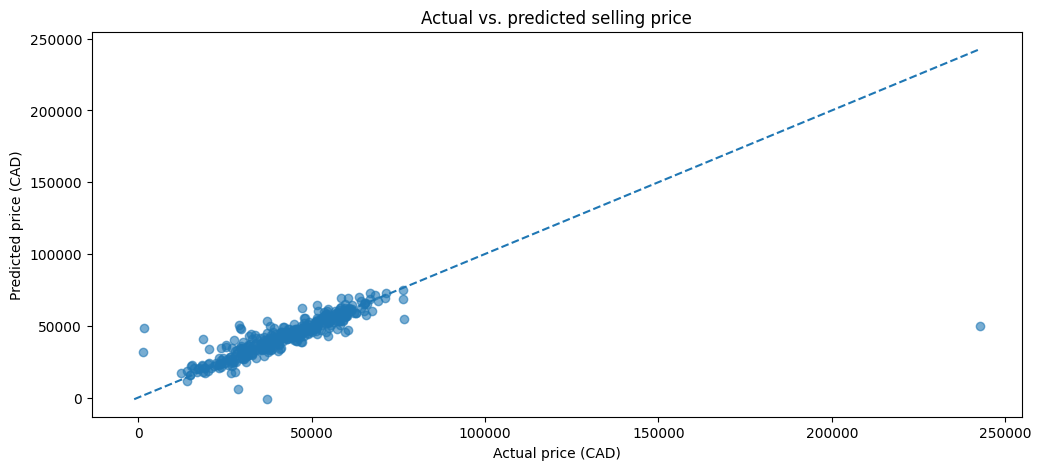

In [98]:
results = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred
})
results["residual"] = results["actual"] - results["predicted"]

fig, axes = plt.subplots(figsize=(12, 5))
axes.scatter(results["actual"], results["predicted"], alpha=.6)
low = min(results["actual"].min(), results["predicted"].min())
high = max(results["actual"].max(), results["predicted"].max())
axes.plot([low, high], [low, high], linestyle="--")
axes.set_title("Actual vs. predicted selling price")
axes.set_xlabel("Actual price (CAD)")
axes.set_ylabel("Predicted price (CAD)")

## Reflection and limitations

Interpret the held-out MAE in practical terms: it is the average absolute miss in Canadian dollars, and its percentage of the mean test price provides context for dealership use. Compare the model with the simple training-mean baseline; the regression is useful only if it improves on that baseline. The diagnostic plots should be checked for compression toward the middle, outliers, and patterns in residuals.

This is a baseline linear model. Price relationships may be nonlinear (for example, depreciation by model year and mileage), and interactions between make/model, age, condition, and drivetrain may matter. High-cardinality categories such as MODEL can also create many sparse indicators. The test metrics estimate performance on a random holdout from this dataset, not necessarily on future listings or a changing market; performance should be monitored on newer sales before operational use.